# Weekly active users forecast

Holt-Winters exponential smoothing (additive trend, weekly seasonality) on DAU and WAU, back-tested on the last 14 days, then a 28-day forecast with simulated prediction intervals.

In [1]:
import json, warnings
from pathlib import Path
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
EXTRACTS, IMAGES = ROOT / "data" / "extracts", ROOT / "docs" / "images"
IMAGES.mkdir(parents=True, exist_ok=True)

# Query the warehouse marts through their Parquet extracts (lock-free while dbt runs)
con = duckdb.connect()
for p in EXTRACTS.glob("*/data.parquet"):
    con.execute(f"create or replace view {p.parent.name} as select * from read_parquet('{p.as_posix()}')")
q = lambda sql: con.execute(sql).df()

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.titlesize": 12, "font.size": 10})

from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [2]:
s = q("select activity_date, dau, wau from mtr_daily_active_users order by 1").set_index("activity_date")
s.index = pd.DatetimeIndex(s.index, freq="D")
H = 14
results = {}
for col in ["dau", "wau"]:
    y = s[col].astype(float).iloc[7:]          # skip the launch week (WAU window not full)
    train, test = y.iloc[:-H], y.iloc[-H:]
    m = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=7).fit()
    pred = m.forecast(H)
    mape = (np.abs(pred - test) / test).mean()
    naive = (np.abs(train.iloc[-7:].values.repeat(2)[:H] - test.values) / test.values).mean()
    results[col] = dict(mape=mape, seasonal_naive_mape=naive)
pd.DataFrame(results).T.style.format("{:.2%}")

,mape,seasonal_naive_mape
dau,3.70%,13.93%
wau,2.05%,8.40%


DAU in 28 days: 10,860  (90% PI 10,258–11,236)


WAU in 28 days: 24,790  (90% PI 20,884–29,029)


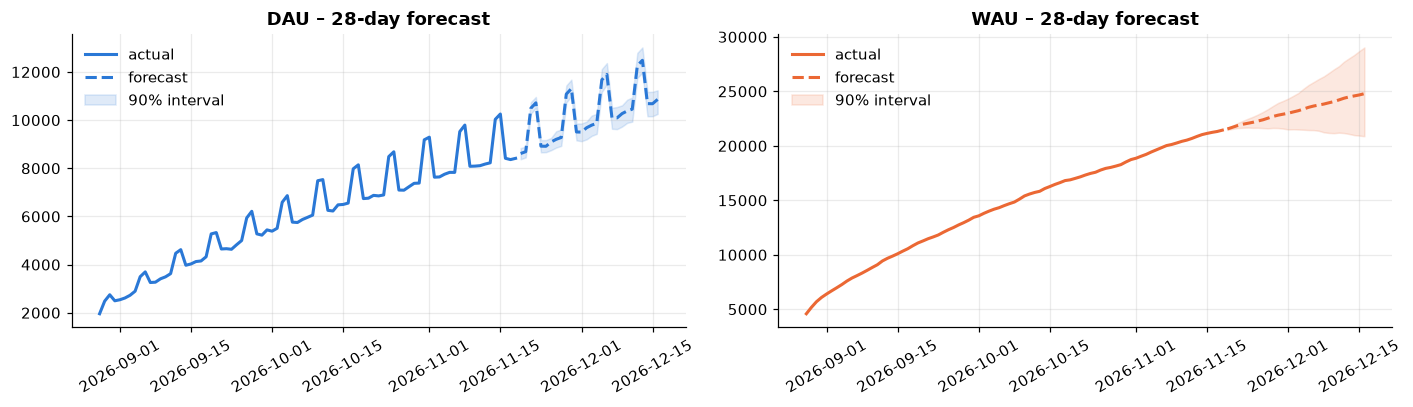

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col, color in zip(axes, ["dau", "wau"], [BLUE, ORANGE]):
    y = s[col].astype(float).iloc[7:]
    m = ExponentialSmoothing(y, trend="add", seasonal="add", seasonal_periods=7).fit()
    fc = m.forecast(28)
    sims = m.simulate(28, repetitions=500, error="add", anchor="end")
    lo, hi = np.percentile(sims, 5, axis=1), np.percentile(sims, 95, axis=1)
    ax.plot(y.index, y, color=color, lw=2, label="actual")
    ax.plot(fc.index, fc, color=color, lw=2, ls="--", label="forecast")
    ax.fill_between(fc.index, lo, hi, color=color, alpha=.15, label="90% interval")
    ax.set_title(f"{col.upper()} – 28-day forecast"); ax.legend(frameon=False, loc="upper left")
    ax.tick_params(axis="x", rotation=30)
    print(f"{col.upper()} in 28 days: {fc.iloc[-1]:,.0f}  (90% PI {lo[-1]:,.0f}–{hi[-1]:,.0f})")
plt.tight_layout(); plt.savefig(IMAGES / "forecast.png", bbox_inches="tight"); plt.show()

**Caveats.** 90 days is short; trend extrapolation assumes acquisition keeps growing linearly. In production this would be re-fit daily by an Airflow task and compared with a cohort-based model (signup forecast × retention curve).